# How did Chelsea go from 10th to champions?

In 2015/16 Chelsea finished **10th**, their lowest Premier League finish in 20 years, and sacked José Mourinho in December.
A year later, under Antonio Conte, they won the league with **93 points** and a record **30 wins**.

This notebook asks four questions:

1. **Were they the best team, or the luckiest?** Points vs expected points (xPts) from every shot's xG.
2. **What did the switch to three at the back change?** Matches 1–6 (back four) vs 7–38 (3–4–3, from 1 October 2016).
3. **How did 10th become 1st?** Both seasons on the same xG model.
4. **Where did the extra goals come from?** Finishing, set pieces, penalties.

**Data:** [Understat](https://understat.com) xG for every shot in 2015/16 and 2016/17, from the public copy at
[douglasbc/scraping-understat-dataset](https://github.com/douglasbc/scraping-understat-dataset).
Download with `python -m football_analytics.understat 15-16 16-17` from the repo root.

In [1]:
from pathlib import Path
import html
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # project folder
REPO = next(p for p in [ROOT, *ROOT.parents] if (p / "src" / "football_analytics").exists())  # repo root
sys.path.insert(0, str(REPO / "src"))
from football_analytics.viz import leaderboard

U = REPO / "data" / "raw" / "understat"
EXT = ROOT / "data" / "external"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
CHE = "Chelsea"
BLUE, GREY, DARK, MUTED, GOLD = "#1F5FAD", "#B4B2A9", "#3D3D3A", "#6B6A64", "#FDBE11"
GOLD_TEXT = "#9A7200"  # darker gold for text on white
SRC_U = "Data: Understat (via douglasbc/scraping-understat-dataset)"
SRC_PL = "Data: Premier League official stats (Opta), premierleague.com"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": DARK, "xtick.color": DARK, "ytick.color": DARK,
    "axes.grid": True, "grid.color": "#ECEAE4", "grid.linewidth": 0.8, "axes.axisbelow": True,
})


def titles(fig, title, subtitle, source):
    """Title above the axes (va=bottom) and subtitle just under it (va=top) so they never overlap."""
    fig.suptitle(title, x=0.01, y=1.06, ha="left", va="bottom", fontsize=14, fontweight="bold", color=DARK)
    fig.text(0.01, 1.055, subtitle, ha="left", va="top", fontsize=10, color=MUTED)
    fig.text(0.01, -0.04, source, ha="left", va="top", fontsize=8, color=MUTED)


def load_shots(season):
    d = pd.read_csv(U / f"shots_epl_{season}.csv")
    d["team"] = np.where(d.h_a == "h", d.h_team, d.a_team)
    d["opp"] = np.where(d.h_a == "h", d.a_team, d.h_team)
    d["goal"] = d.result == "Goal"
    d["date"] = pd.to_datetime(d.date)
    d["player"] = d.player.map(html.unescape)
    return d


def load_players(season):
    p = pd.read_csv(U / f"players_epl_{season}.csv")
    p["player_name"] = p.player_name.map(html.unescape)
    p["team"] = p.team_title.str.split(",").str[-1]  # players who moved mid-season: last club
    return p


def matches(shots):
    """One row per team per match: goals, xG for and against, points."""
    g = shots.groupby("match_id").agg(date=("date", "first"), h=("h_team", "first"), a=("a_team", "first"),
                                      hg=("h_goals", "first"), ag=("a_goals", "first"))
    xg = shots.groupby(["match_id", "team"]).xG.sum()
    rows = []
    for mid, r in g.iterrows():
        for team, opp, gf, ga in [(r.h, r.a, r.hg, r.ag), (r.a, r.h, r.ag, r.hg)]:
            rows.append(dict(match_id=mid, date=r.date, team=team, opp=opp, home=team == r.h, gf=gf, ga=ga,
                             xgf=xg.get((mid, team), 0.0), xga=xg.get((mid, opp), 0.0),
                             pts=3 if gf > ga else 1 if gf == ga else 0))
    m = pd.DataFrame(rows).sort_values(["team", "date"])
    m["n"] = m.groupby("team").cumcount() + 1
    return m


def expected_points(shots, sims=10_000, seed=42):
    """Replay every match `sims` times: each shot is a goal with probability = its xG."""
    rng = np.random.default_rng(seed)
    out = {}
    for mid, g in shots.groupby("match_id"):
        h, a = g.h_team.iloc[0], g.a_team.iloc[0]
        hx, ax = g[g.team == h].xG.values, g[g.team == a].xG.values
        sh = (rng.random((sims, len(hx))) < hx).sum(1)
        sa = (rng.random((sims, len(ax))) < ax).sum(1)
        out[(mid, h)] = (3 * (sh > sa) + (sh == sa)).mean()
        out[(mid, a)] = (3 * (sa > sh) + (sa == sh)).mean()
    return pd.Series(out, name="xpts")

In [2]:
S = {"2015/16": load_shots("15-16"), "2016/17": load_shots("16-17")}
M = {k: matches(v) for k, v in S.items()}
for k, m in M.items():
    print(k, m.match_id.nunique(), "matches;", "Chelsea", m[m.team == CHE].pts.sum(), "points,",
          int(m[m.team == CHE].gf.sum()), "scored,", int(m[m.team == CHE].ga.sum()), "conceded")

2015/16 380 matches; Chelsea 50 points, 59 scored, 53 conceded
2016/17 380 matches; Chelsea 93 points, 85 scored, 33 conceded


## 1. Were they the best team, or the luckiest?

Each match is replayed 10,000 times: every shot goes in with probability equal to its xG. A team's **expected points** is its
average haul across those replays: the points its chances were worth.

In [3]:
def table(season):
    m = M[season].merge(expected_points(S[season]).rename_axis(["match_id", "team"]).reset_index(), on=["match_id", "team"])
    t = m.groupby("team").agg(pts=("pts", "sum"), xpts=("xpts", "sum"), gf=("gf", "sum"), ga=("ga", "sum"),
                              xgf=("xgf", "sum"), xga=("xga", "sum"))
    t["gap"] = t.pts - t.xpts
    t["xrank"] = t.xpts.rank(ascending=False).astype(int)
    return t.sort_values("pts", ascending=False)

T = {k: table(k) for k in S}
T["2016/17"].round(1).head(8)

,pts,xpts,gf,ga,xgf,xga,gap,xrank
team,,,,,,,,
Chelsea,93,76.1,85.0,33.0,62.4,28.7,16.9,2
Tottenham,86,75.4,86.0,26.0,71.0,34.3,10.6,3
Manchester City,78,85.1,80.0,39.0,80.6,30.1,-7.1,1
Liverpool,76,69.7,78.0,42.0,67.4,38.6,6.3,5
Arsenal,75,62.3,77.0,44.0,65.0,47.5,12.7,6
Manchester United,69,71.4,54.0,29.0,58.7,31.7,-2.4,4
Everton,61,55.5,62.0,44.0,49.9,46.5,5.5,8
Bournemouth,46,43.6,55.0,67.0,51.1,63.6,2.4,14


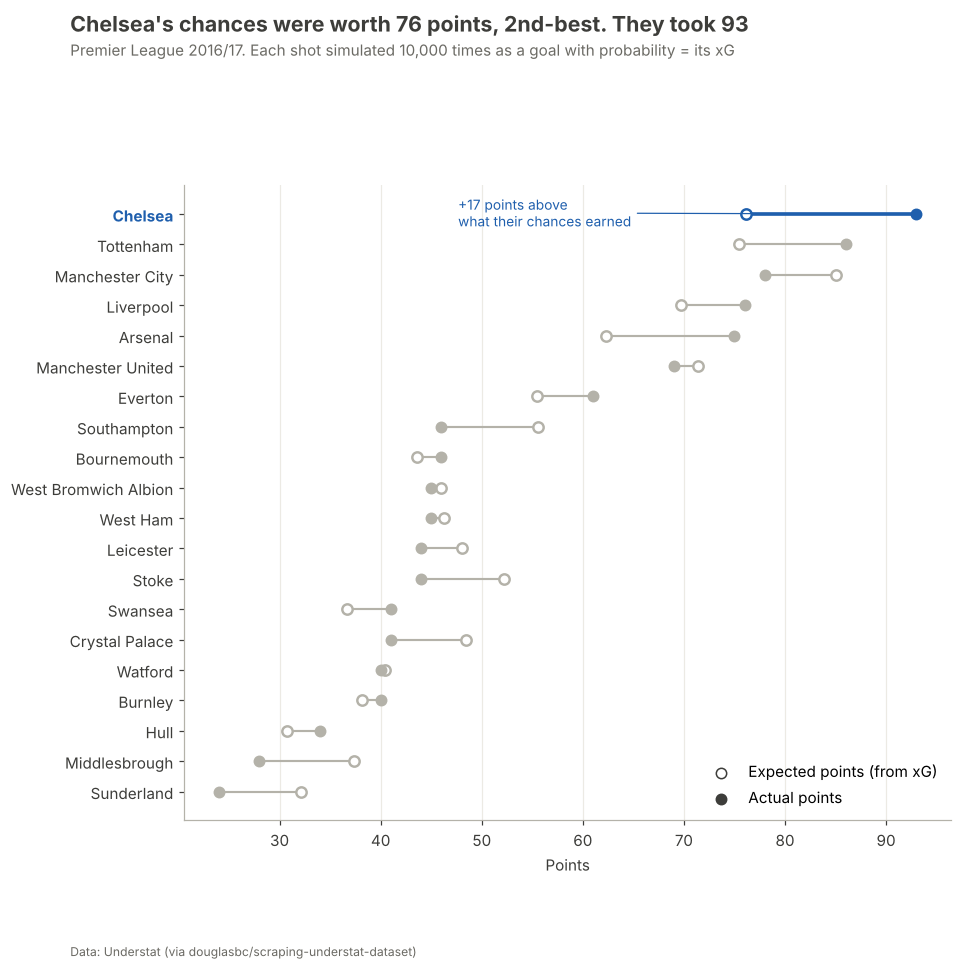

In [4]:
t = T["2016/17"].sort_values("pts")
fig, ax = plt.subplots(figsize=(9, 7.5))
y = np.arange(len(t))
for yi, (team, r) in zip(y, t.iterrows()):
    c = BLUE if team == CHE else GREY
    ax.plot([r.xpts, r.pts], [yi, yi], color=c, lw=2.4 if team == CHE else 1.4, zorder=1)
    ax.scatter(r.xpts, yi, s=46, facecolor="white", edgecolor=c, lw=1.6, zorder=2)
    ax.scatter(r.pts, yi, s=46, color=c, zorder=3)
ax.set_yticks(y, t.index)
for lab in ax.get_yticklabels():
    if lab.get_text() == CHE:
        lab.set_color(BLUE); lab.set_fontweight("bold")
c = t.loc[CHE]
ax.annotate(f"+{c.gap:.0f} points above\nwhat their chances earned", (c.pts, y[list(t.index).index(CHE)]),
            xytext=(-300, -8), textcoords="offset points", color=BLUE, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=BLUE, lw=0.8))
ax.scatter([], [], s=46, facecolor="white", edgecolor=DARK, label="Expected points (from xG)")
ax.scatter([], [], s=46, color=DARK, label="Actual points")
ax.legend(loc="lower right", frameon=False)
ax.set_xlabel("Points")
ax.grid(axis="y", visible=False)
titles(fig, f"Chelsea's chances were worth {c.xpts:.0f} points, {c.xrank:.0f}nd-best. They took {c.pts:.0f}",
       "Premier League 2016/17. Each shot simulated 10,000 times as a goal with probability = its xG", SRC_U)
fig.savefig(FIGS / "01_points_vs_expected_points.png")

**Finding:** on chances alone Chelsea were the **2nd-best** team (behind Manchester City) and won the league by 7 points
anyway, finishing about 17 points above their expected total, the biggest gap in the league.

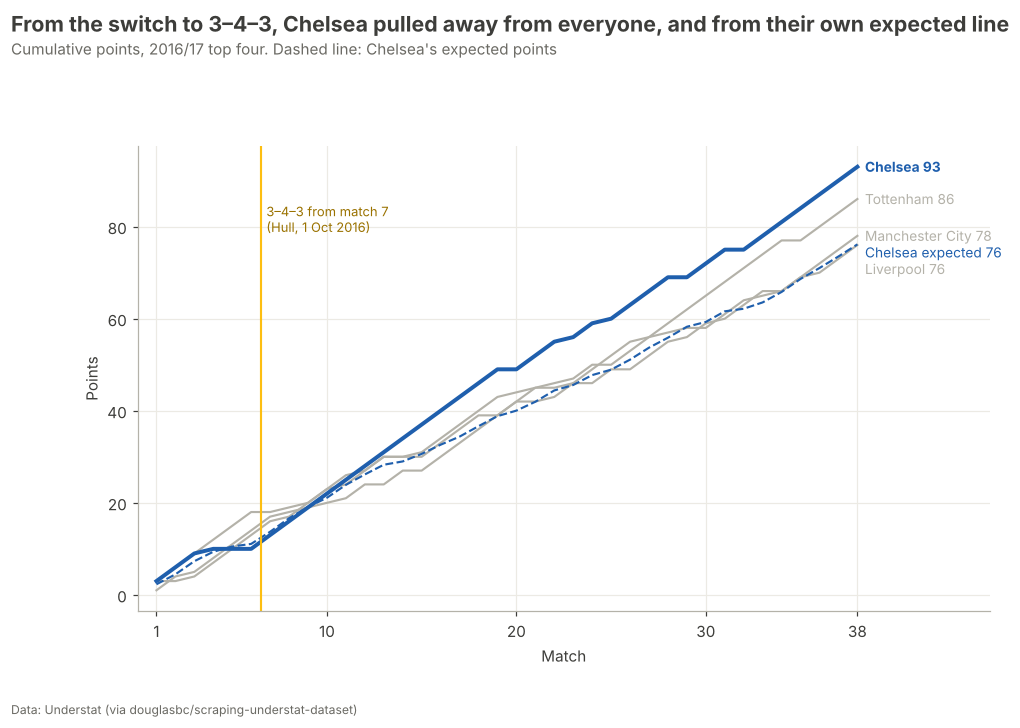

In [5]:
top = T["2016/17"].index[:4]
fig, ax = plt.subplots(figsize=(10, 5.5))
labels = []
for team in top[::-1]:
    m = M["2016/17"][M["2016/17"].team == team]
    c = BLUE if team == CHE else GREY
    ax.plot(m.n, m.pts.cumsum(), color=c, lw=2.6 if team == CHE else 1.4)
    labels.append([m.pts.sum(), f"{team} {m.pts.sum()}", c, team == CHE])
xp = M["2016/17"][M["2016/17"].team == CHE].merge(
    expected_points(S["2016/17"]).rename_axis(["match_id", "team"]).reset_index(), on=["match_id", "team"])
ax.plot(xp.n, xp.xpts.cumsum(), color=BLUE, lw=1.4, ls="--")
labels.append([xp.xpts.sum(), f"Chelsea expected {xp.xpts.sum():.0f}", BLUE, False])
labels.sort(key=lambda l: -l[0])
for i in range(1, len(labels)):  # keep end labels at least 3.6 points apart
    labels[i][0] = min(labels[i][0], labels[i - 1][0] - 3.6)
for yv, text, c, bold in labels:
    ax.text(38.4, yv, text, va="center", fontsize=9, color=c, fontweight="bold" if bold else "normal")
ax.axvline(6.5, color=GOLD, lw=1.4)
ax.text(6.8, 85, "3–4–3 from match 7\n(Hull, 1 Oct 2016)", fontsize=8.5, color=GOLD_TEXT, va="top")
ax.set_xlim(0, 45); ax.set_xticks([1, 10, 20, 30, 38])
ax.set_xlabel("Match"); ax.set_ylabel("Points")
titles(fig, "From the switch to 3–4–3, Chelsea pulled away from everyone, and from their own expected line",
       "Cumulative points, 2016/17 top four. Dashed line: Chelsea's expected points", SRC_U)
fig.savefig(FIGS / "02_title_race.png")

## 2. What did the switch to three at the back change?

After losses to Liverpool and Arsenal (0–3 on 24 September), Conte moved to a **3–4–3** against Hull on 1 October 2016:
Azpilicueta, Luiz and Cahill at the back, Moses and Alonso as wing-backs. Matches 1–6 used a back four; 7–38 the back three.

In [6]:
che = M["2016/17"][M["2016/17"].team == CHE].copy()
che["era"] = np.where(che.n <= 6, "Back four (1–6)", "3–4–3 (7–38)")
shots_against = S["2016/17"][(S["2016/17"].opp == CHE)].groupby("match_id").size()
che["shots_against"] = che.match_id.map(shots_against).fillna(0)
split = che.groupby("era", sort=False)[["pts", "gf", "ga", "xgf", "xga", "shots_against"]].mean()
split.round(2)

,pts,gf,ga,xgf,xga,shots_against
era,,,,,,
Back four (1–6),1.67,1.67,1.50,1.64,0.96,8.67
3–4–3 (7–38),2.59,2.34,0.75,1.64,0.72,8.53


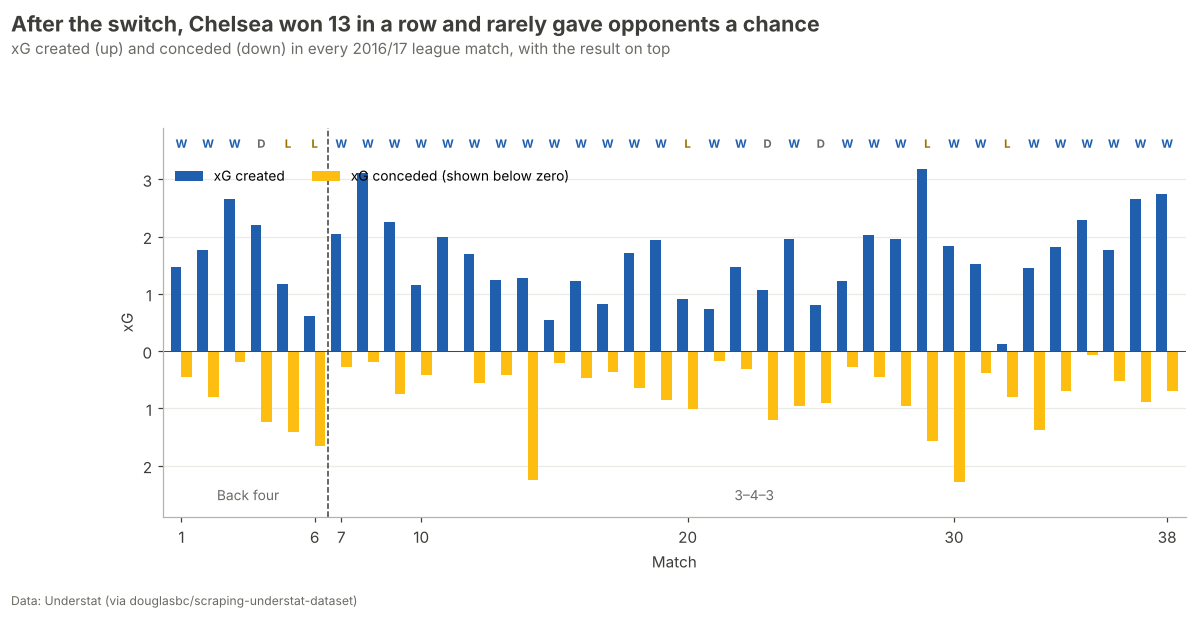

In [7]:
fig, ax = plt.subplots(figsize=(12, 4.6))
x = che.n.values
ax.bar(x - 0.2, che.xgf, width=0.4, color=BLUE, label="xG created")
ax.bar(x + 0.2, -che.xga, width=0.4, color=GOLD, label="xG conceded (shown below zero)")
for xi, r in zip(x, che.itertuples()):
    res = "W" if r.pts == 3 else "D" if r.pts == 1 else "L"
    ax.text(xi, 3.55, res, ha="center", fontsize=7.5, color=BLUE if res == "W" else GOLD_TEXT if res == "L" else MUTED,
            fontweight="bold")
ax.axvline(6.5, color=DARK, lw=1, ls="--")
ax.text(3.5, -2.6, "Back four", ha="center", fontsize=9, color=MUTED)
ax.text(22.5, -2.6, "3–4–3", ha="center", fontsize=9, color=MUTED)
ax.axhline(0, color=DARK, lw=0.6)
ax.set_xlim(0.3, 38.7); ax.set_ylim(-2.9, 3.9)
ax.set_xticks([1, 6, 7, 10, 20, 30, 38]); ax.set_xlabel("Match")
ax.set_yticks([-2, -1, 0, 1, 2, 3], ["2", "1", "0", "1", "2", "3"]); ax.set_ylabel("xG")
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.93), frameon=False, ncol=2, fontsize=9)
ax.grid(axis="x", visible=False)
titles(fig, "After the switch, Chelsea won 13 in a row and rarely gave opponents a chance",
       "xG created (up) and conceded (down) in every 2016/17 league match, with the result on top", SRC_U)
fig.savefig(FIGS / "03_every_match_2016_17.png")

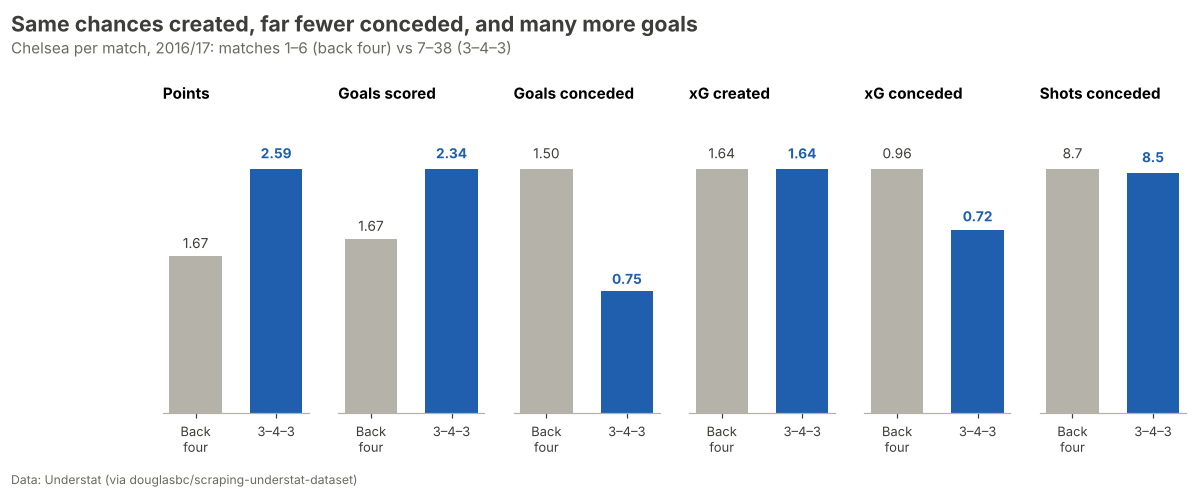

In [8]:
labels = {"pts": "Points", "gf": "Goals scored", "ga": "Goals conceded", "xgf": "xG created", "xga": "xG conceded",
          "shots_against": "Shots conceded"}
fig, axes = plt.subplots(1, 6, figsize=(12, 3.6))
for ax, (col, lab) in zip(axes, labels.items()):
    v = split[col].values
    ax.bar([0, 1], v, color=[GREY, BLUE], width=0.65)
    for i, val in enumerate(v):
        ax.text(i, val * 1.03, f"{val:.2f}" if col != "shots_against" else f"{val:.1f}", ha="center", va="bottom",
                fontsize=9, color=BLUE if i else DARK, fontweight="bold" if i else "normal")
    ax.set_title(lab, fontsize=10)
    ax.set_xticks([0, 1], ["Back\nfour", "3–4–3"], fontsize=8.5)
    ax.set_yticks([]); ax.set_ylim(0, v.max() * 1.25)
    ax.spines["left"].set_visible(False); ax.grid(False)
titles(fig, "Same chances created, far fewer conceded, and many more goals",
       "Chelsea per match, 2016/17: matches 1–6 (back four) vs 7–38 (3–4–3)", SRC_U)
fig.savefig(FIGS / "04_before_after_switch.png")

**Finding:** xG created per match was **identical** before and after the switch. What changed was the other end
(fewer shots and less xG conceded) and the finishing: the same chances produced far more goals.

## 3. How did 10th become 1st?

Both seasons on the same model. Expected points for every team in 2015/16 and 2016/17.

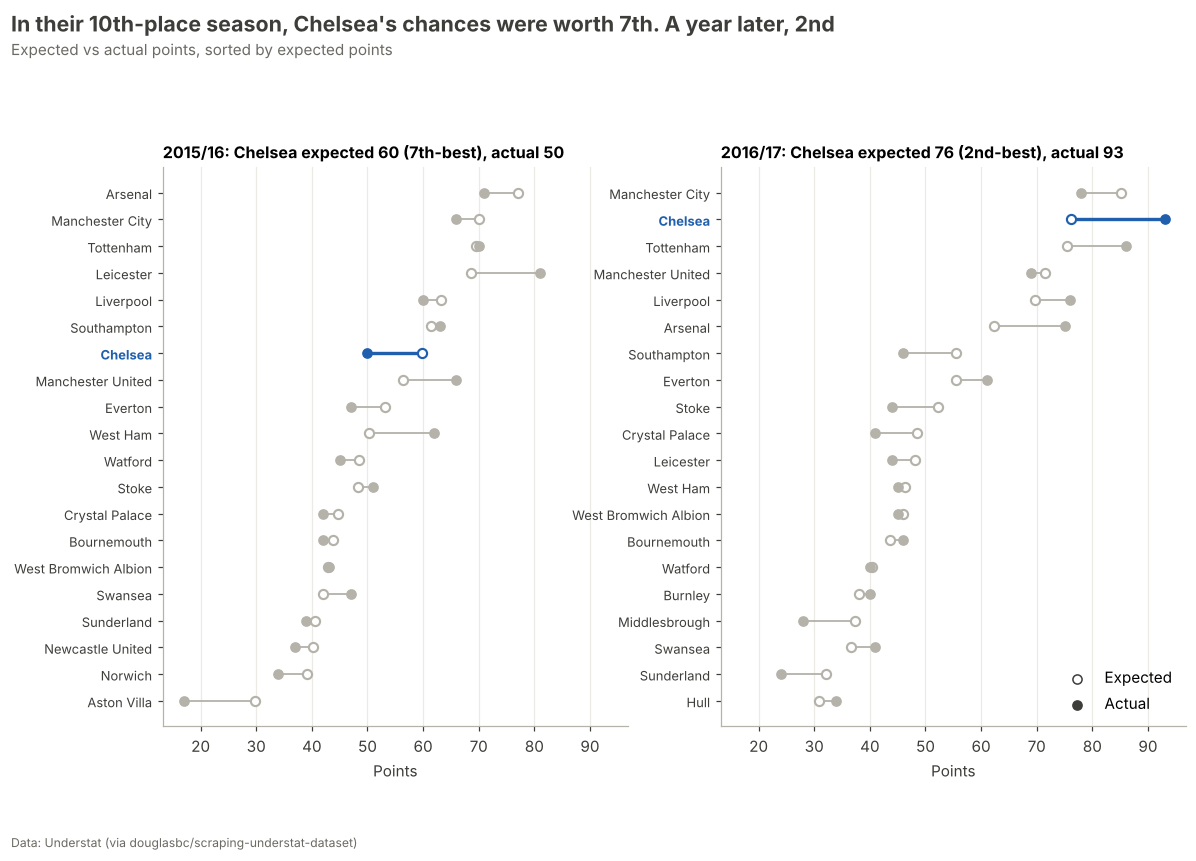

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6.6), sharex=True)
for ax, season in zip(axes, ["2015/16", "2016/17"]):
    t = T[season].sort_values("xpts")
    y = np.arange(len(t))
    for yi, (team, r) in zip(y, t.iterrows()):
        c = BLUE if team == CHE else GREY
        ax.plot([r.xpts, r.pts], [yi, yi], color=c, lw=2.2 if team == CHE else 1.2)
        ax.scatter(r.xpts, yi, s=36, facecolor="white", edgecolor=c, lw=1.4, zorder=2)
        ax.scatter(r.pts, yi, s=36, color=c, zorder=3)
    ax.set_yticks(y, t.index, fontsize=8.5)
    for lab in ax.get_yticklabels():
        if lab.get_text() == CHE:
            lab.set_color(BLUE); lab.set_fontweight("bold")
    r = t.loc[CHE]
    ax.set_title(f"{season}: Chelsea expected {r.xpts:.0f} ({r.xrank:.0f}th-best), actual {r.pts:.0f}".replace("1th", "1st")
                 .replace("2th", "2nd").replace("3th", "3rd"), fontsize=10.5)
    ax.grid(axis="y", visible=False); ax.set_xlabel("Points")
axes[1].scatter([], [], s=36, facecolor="white", edgecolor=DARK, label="Expected")
axes[1].scatter([], [], s=36, color=DARK, label="Actual")
axes[1].legend(loc="lower right", frameon=False)
titles(fig, "In their 10th-place season, Chelsea's chances were worth 7th. A year later, 2nd",
       "Expected vs actual points, sorted by expected points", SRC_U)
fig.savefig(FIGS / "05_expected_points_both_seasons.png")

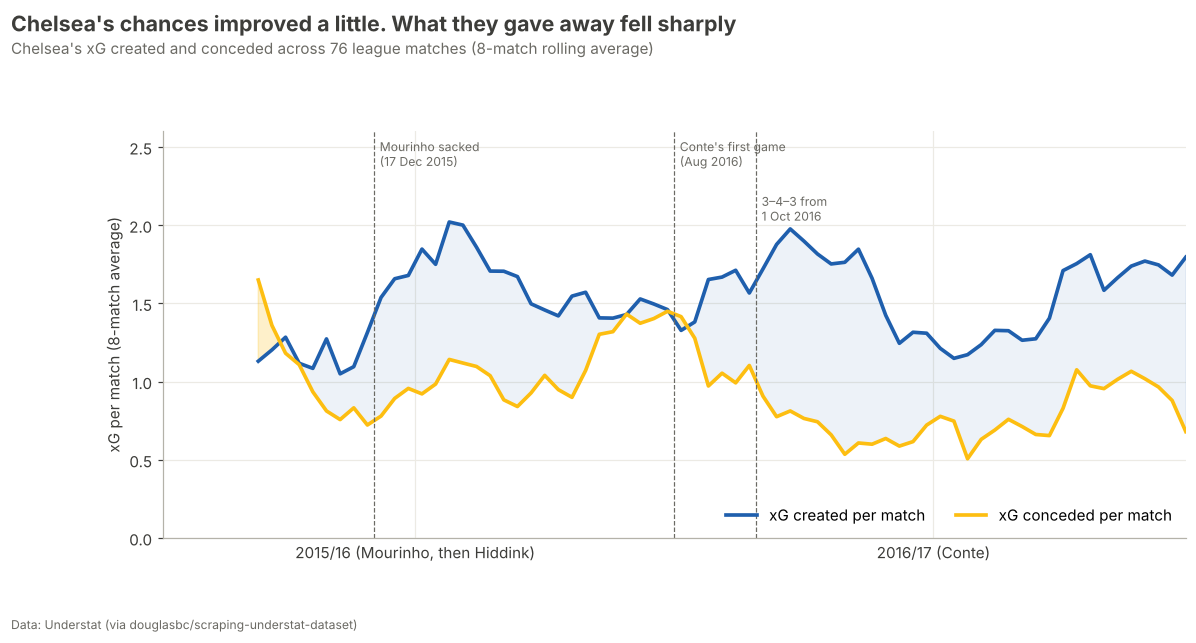

In [10]:
both = pd.concat([M["2015/16"].assign(season="2015/16"), M["2016/17"].assign(season="2016/17")])
c = both[both.team == CHE].sort_values("date").reset_index(drop=True)
c["i"] = np.arange(1, len(c) + 1)
roll = c[["xgf", "xga", "pts"]].rolling(8, min_periods=8).mean()
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(c.i, roll.xgf, color=BLUE, lw=2.4, label="xG created per match")
ax.plot(c.i, roll.xga, color=GOLD, lw=2.4, label="xG conceded per match")
ax.fill_between(c.i, roll.xgf, roll.xga, where=roll.xgf >= roll.xga, color=BLUE, alpha=0.08, interpolate=True)
ax.fill_between(c.i, roll.xgf, roll.xga, where=roll.xgf < roll.xga, color=GOLD, alpha=0.22, interpolate=True)
for xpos, label, ytxt in [(16.5, "Mourinho sacked\n(17 Dec 2015)", 2.55), (38.5, "Conte's first game\n(Aug 2016)", 2.55),
                    (44.5, "3–4–3 from\n1 Oct 2016", 2.2)]:
    ax.axvline(xpos, color=MUTED, lw=0.8, ls="--")
    ax.text(xpos + 0.4, ytxt, label, fontsize=8, color=MUTED, va="top")
ax.set_ylim(0, 2.6); ax.set_xlim(1, 76)
ax.set_xticks([19.5, 57.5], ["2015/16 (Mourinho, then Hiddink)", "2016/17 (Conte)"])
ax.tick_params(axis="x", length=0)
ax.set_ylabel("xG per match (8-match average)")
ax.legend(loc="lower right", frameon=False, ncol=2)
titles(fig, "Chelsea's chances improved a little. What they gave away fell sharply",
       "Chelsea's xG created and conceded across 76 league matches (8-match rolling average)", SRC_U)
fig.savefig(FIGS / "06_xg_timeline_two_seasons.png")

## 4. Where did the extra goals come from?

Non-penalty goals minus non-penalty xG for every team in 2016/17: how far each team's finishing beat (or missed) its chances.

,npg,npxg,diff
team,,,
Everton,55,46.8,8.2
Arsenal,69,60.4,8.6
Liverpool,70,61.3,8.7
Tottenham,77,64.2,12.8
Chelsea,81,59.4,21.6


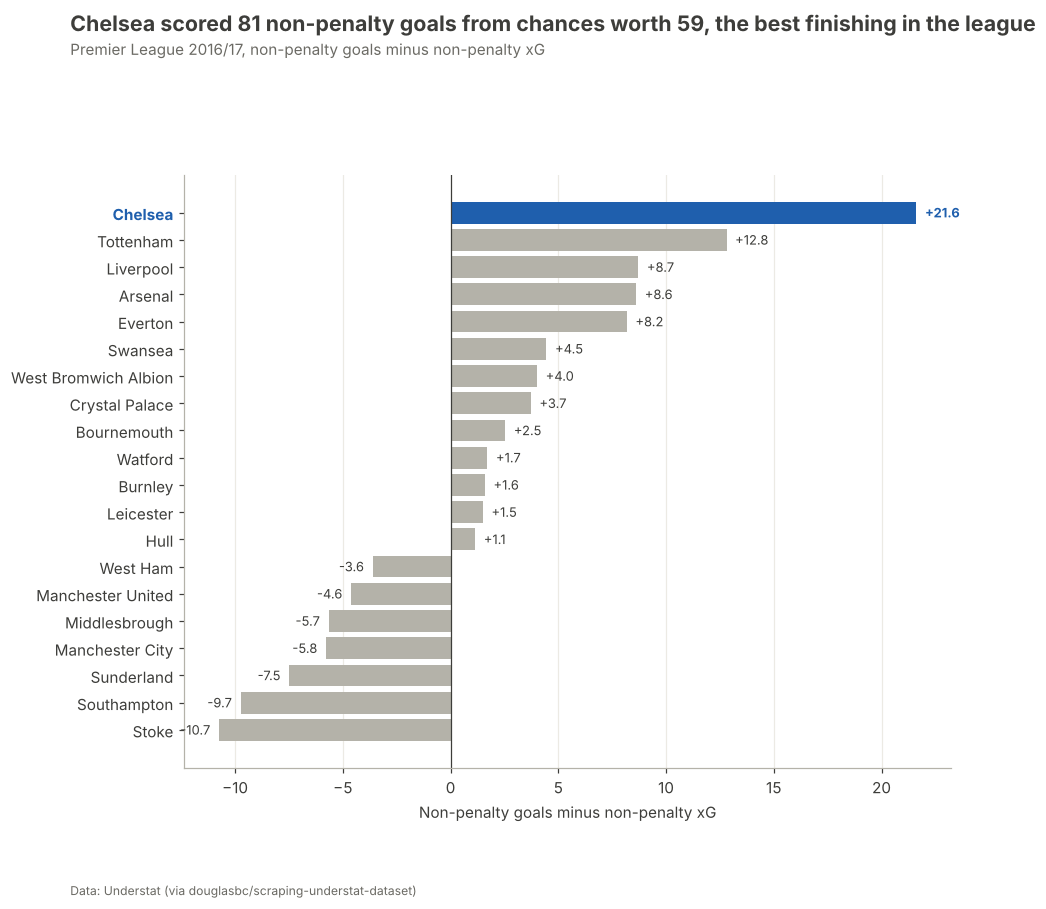

In [11]:
s = S["2016/17"]; np_ = s[s.situation != "Penalty"]
fin = np_.groupby("team").agg(npg=("goal", "sum"), npxg=("xG", "sum"))
fin["diff"] = fin.npg - fin.npxg
fin = fin.sort_values("diff")
fig, ax = plt.subplots(figsize=(9, 7))
cols = [BLUE if t == CHE else GREY for t in fin.index]
ax.barh(fin.index, fin["diff"], color=cols)
for i, (t, r) in enumerate(fin.iterrows()):
    ax.text(r["diff"] + (0.4 if r["diff"] >= 0 else -0.4), i, f"{r['diff']:+.1f}", va="center",
            ha="left" if r["diff"] >= 0 else "right", fontsize=8.5, color=BLUE if t == CHE else DARK,
            fontweight="bold" if t == CHE else "normal")
for lab in ax.get_yticklabels():
    if lab.get_text() == CHE:
        lab.set_color(BLUE); lab.set_fontweight("bold")
ax.axvline(0, color=DARK, lw=0.8)
ax.set_xlabel("Non-penalty goals minus non-penalty xG")
ax.grid(axis="y", visible=False)
c = fin.loc[CHE]
titles(fig, f"Chelsea scored {c.npg:.0f} non-penalty goals from chances worth {c.npxg:.0f}, the best finishing in the league",
       "Premier League 2016/17, non-penalty goals minus non-penalty xG", SRC_U)
fig.savefig(FIGS / "07_finishing_by_team.png")
fin.round(1).tail(5)

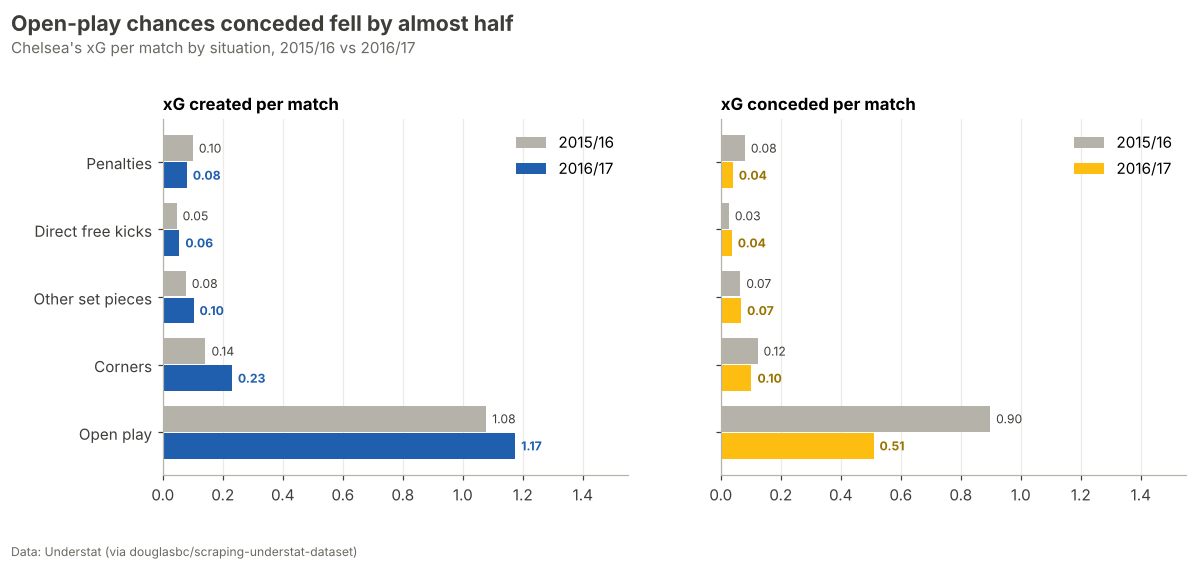

In [12]:
order = ["OpenPlay", "FromCorner", "SetPiece", "DirectFreekick", "Penalty"]
names = {"OpenPlay": "Open play", "FromCorner": "Corners", "SetPiece": "Other set pieces", "DirectFreekick": "Direct free kicks",
         "Penalty": "Penalties"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, side in zip(axes, ["Created", "Conceded"]):
    vals = {}
    for season, s in S.items():
        d = s[s.team == CHE] if side == "Created" else s[s.opp == CHE]
        vals[season] = d.groupby("situation").xG.sum().reindex(order).fillna(0) / 38
    y = np.arange(len(order))
    ax.barh(y + 0.2, vals["2015/16"], height=0.38, color=GREY, label="2015/16")
    ax.barh(y - 0.2, vals["2016/17"], height=0.38, color=BLUE if side == "Created" else GOLD, label="2016/17")
    for yi, v1, v2 in zip(y, vals["2015/16"], vals["2016/17"]):
        ax.text(v1 + 0.02, yi + 0.2, f"{v1:.2f}", va="center", fontsize=8, color=DARK)
        ax.text(v2 + 0.02, yi - 0.2, f"{v2:.2f}", va="center", fontsize=8,
                color=BLUE if side == "Created" else GOLD_TEXT, fontweight="bold")
    ax.set_yticks(y, [names[o] for o in order]); ax.invert_yaxis()
    ax.set_title(f"xG {side.lower()} per match", fontsize=11)
    ax.set_xlim(0, 1.55); ax.grid(axis="y", visible=False)
    ax.legend(loc="upper right", frameon=False)
titles(fig, "Open-play chances conceded fell by almost half",
       "Chelsea's xG per match by situation, 2015/16 vs 2016/17", SRC_U)
fig.savefig(FIGS / "08_xg_by_situation.png")